# Beat 2: Saliency Maps

**Pergunta:** E se eu derivar a saída em relação à imagem?

Este notebook demonstra o gradiente cru ($3\times 224\times 224$), a redução para um canal via $\max|\cdot|$, e a aplicação essencial da escala de exibição (`scale_for_display(high=0.99, gamma=0.5)`).

In [1]:
import os
import sys

sys.path.append(os.path.abspath('.'))
sys.path.append(os.path.abspath('notebooks'))

import torch
import matplotlib.pyplot as plt
from PIL import Image

import deck
from gradcam import saliency_map_fn
from gradcam.models import load_model, preprocess, imagenet_labels, resolve_class, denormalize
from gradcam.viz import figure_grid, overlay, tensor_to_numpy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = load_model("vgg16", device=device)
labels = imagenet_labels()
print(f"VGG-16 carregado em {device}")

VGG-16 carregado em cpu


## Calculando e exibindo o Saliency Map real

Carregando a imagem canônica e calculando o gradiente em relação à classe prevista e a uma classe alternativa.

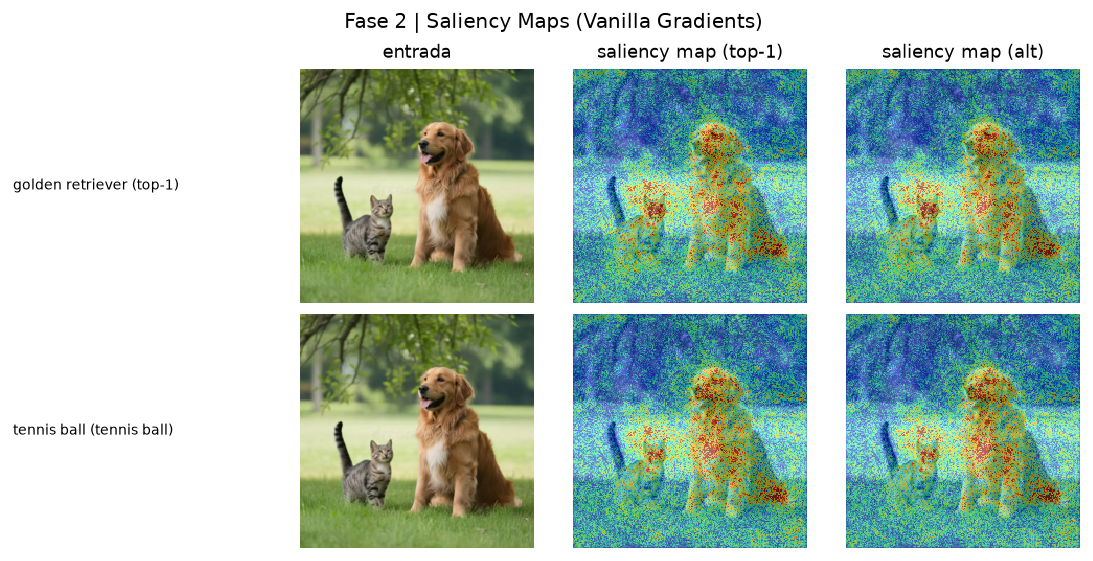

Top-1: golden retriever | min/max mapa: 0.0001 / 0.4466
Alternativo: tennis ball | min/max mapa: 0.0001 / 0.2566


In [2]:
base = "notebooks/assets" if os.path.isdir("notebooks/assets") else "assets"
image = Image.open(os.path.join(base, "cat_dog.jpg")).convert("RGB")
x = preprocess(image)
image_rgb = tensor_to_numpy(denormalize(x))

class_top1 = int(model(x).argmax(dim=1).item())
class_alt = resolve_class("tennis ball", labels)

vanilla_fn = saliency_map_fn("vanilla")
map_top1 = vanilla_fn(model, x, class_top1).detach()
map_alt = vanilla_fn(model, x, class_alt).detach()

DISPLAY_HIGH, DISPLAY_GAMMA = 0.99, 0.5

fig = figure_grid(
    [
        [
            image_rgb,
            overlay(image_rgb, map_top1, high=DISPLAY_HIGH, gamma=DISPLAY_GAMMA),
            overlay(image_rgb, map_top1, high=DISPLAY_HIGH, gamma=DISPLAY_GAMMA),
        ],
        [
            image_rgb,
            overlay(image_rgb, map_alt, high=DISPLAY_HIGH, gamma=DISPLAY_GAMMA),
            overlay(image_rgb, map_alt, high=DISPLAY_HIGH, gamma=DISPLAY_GAMMA),
        ],
    ],
    col_titles=("entrada", "saliency map (top-1)", "saliency map (alt)"),
    row_titles=[
        f"{labels[class_top1]} (top-1)",
        f"{labels[class_alt]} (tennis ball)",
    ],
    suptitle="Fase 2 | Saliency Maps (Vanilla Gradients)",
)
plt.show()

print(f"Top-1: {labels[class_top1]} | min/max mapa: {map_top1.min():.4f} / {map_top1.max():.4f}")
print(f"Alternativo: {labels[class_alt]} | min/max mapa: {map_alt.min():.4f} / {map_alt.max():.4f}")